In [1]:
import pandas as pd

df = pd.read_csv("shopify_stock.csv")

df["date"] = pd.to_datetime(df["date"])

print(df.head())

                        date   open   high    low  close  adj_close     volume
0  2015-05-21 00:00:00-04:00  2.800  2.874  2.411  2.568      2.568  123039000
1  2015-05-22 00:00:00-04:00  2.607  3.110  2.600  2.831      2.831   28412000
2  2015-05-26 00:00:00-04:00  2.980  3.034  2.908  2.965      2.965    8202000
3  2015-05-27 00:00:00-04:00  3.067  3.081  2.700  2.750      2.750    7976000
4  2015-05-28 00:00:00-04:00  2.755  2.774  2.648  2.745      2.745    4000000


/tmp/ipykernel_2390/891450654.py:5: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df["date"] = pd.to_datetime(df["date"])


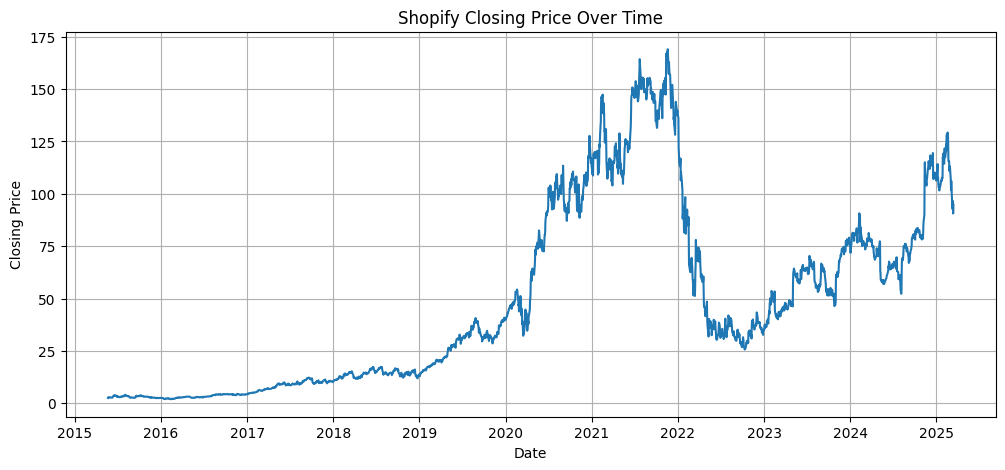

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(df["date"], df["close"])

plt.title("Shopify Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)

plt.show()

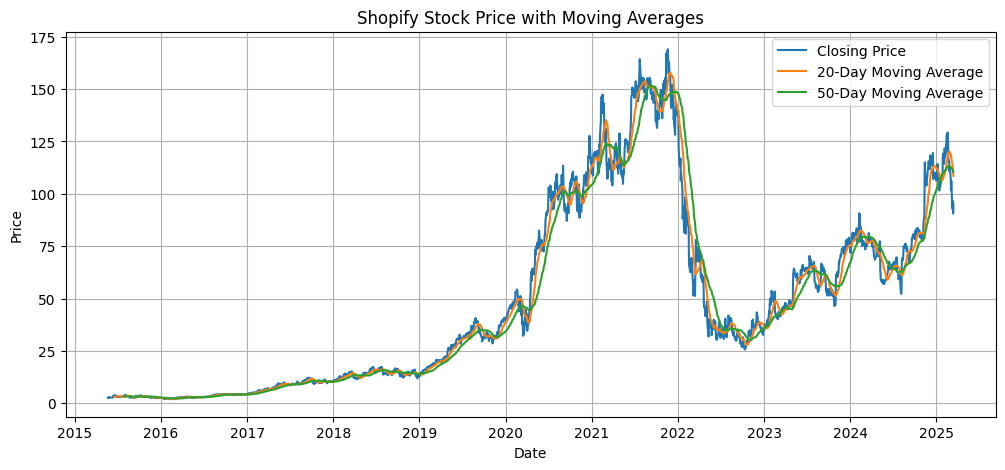

In [3]:
df["MA20"] = df["close"].rolling(window=20).mean()
df["MA50"] = df["close"].rolling(window=50).mean()

plt.figure(figsize=(12, 5))

plt.plot(df["date"], df["close"], label="Closing Price")
plt.plot(df["date"], df["MA20"], label="20-Day Moving Average")
plt.plot(df["date"], df["MA50"], label="50-Day Moving Average")

plt.title("Shopify Stock Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.show()

In [4]:
df["Daily_Return"] = df["close"].pct_change()

print(df[["date", "close", "Daily_Return"]].head(10))

                        date  close  Daily_Return
0  2015-05-21 00:00:00-04:00  2.568           NaN
1  2015-05-22 00:00:00-04:00  2.831      0.102414
2  2015-05-26 00:00:00-04:00  2.965      0.047333
3  2015-05-27 00:00:00-04:00  2.750     -0.072513
4  2015-05-28 00:00:00-04:00  2.745     -0.001818
5  2015-05-29 00:00:00-04:00  2.720     -0.009107
6  2015-06-01 00:00:00-04:00  2.733      0.004779
7  2015-06-02 00:00:00-04:00  2.695     -0.013904
8  2015-06-03 00:00:00-04:00  2.744      0.018182
9  2015-06-04 00:00:00-04:00  2.678     -0.024052


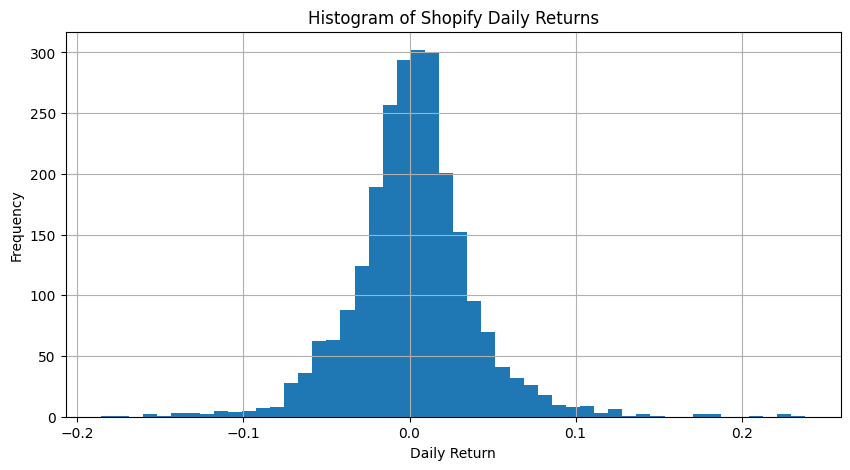

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(df["Daily_Return"].dropna(), bins=50)

plt.title("Histogram of Shopify Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

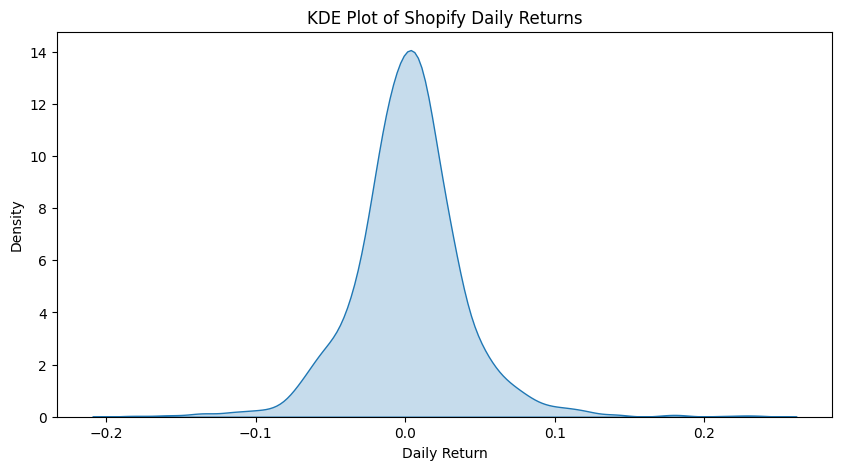

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.kdeplot(df["Daily_Return"].dropna(), fill=True)

plt.title("KDE Plot of Shopify Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Density")

plt.show()

In [7]:
start_price = df["close"].iloc[0]
end_price = df["close"].iloc[-1]

if end_price > start_price:
    print("1. Stock Price Trend: Shopify stock shows an overall upward trend.")
else:
    print("1. Stock Price Trend: Shopify stock shows an overall downward trend.")

1. Stock Price Trend: Shopify stock shows an overall upward trend.


In [8]:
volatility = df["Daily_Return"].std()

print("2. Stock Stability / Volatility:")
print("Daily return standard deviation:", volatility)

if volatility < 0.02:
    print("The stock is relatively stable.")
else:
    print("The stock is relatively volatile.")

2. Stock Stability / Volatility:
Daily return standard deviation: 0.03712243534903455
The stock is relatively volatile.


In [9]:
df["Rolling_Volatility"] = df["Daily_Return"].rolling(window=20).std()

max_date = df.loc[df["Rolling_Volatility"].idxmax(), "date"]
max_volatility = df["Rolling_Volatility"].max()

print("3. High-Volatility Period:")
print("Date:", max_date)
print("Highest 20-day rolling volatility:", max_volatility)

3. High-Volatility Period:
Date: 2022-03-31 00:00:00-04:00
Highest 20-day rolling volatility: 0.08336870148806906
